# **Midterm Project: Data Preprocessing**
## MEXE 4102 – Electives 2 | Pokémon Card Sold-Price Reference Dataset

## Introduction to the Pokémon Card Sold-Price Reference Dataset

- *Pokémon Card Sold-Price Reference by Grade (2026)* (Kaggle, `gemsnipe-card-sold-price-reference.csv`): **508 cards** with median sold prices for raw, PSA 9 and PSA 10 copies, sample counts and confidence labels.
- Key features:
  - **Identifiers / text**: `name`, `set_name`, `local_id`, `tcgdex_id`
  - **Numerical (prices in USD)**: `raw_price_usd`, `psa9_price_usd`, `psa10_price_usd`
  - **Numerical (counts / ratio)**: `raw_sample_count`, `psa9_sample_count`, `psa10_sample_count`, `graded_sales_total`, `psa10_over_psa9_multiple`
  - **Ordinal**: `raw_confidence`, `psa10_confidence` (low < medium < high)

### Preprocessing Techniques We'll Use:
1. **Data Cleaning** – check missing values, duplicate cards and wrong data types.
2. **Data Transformation** – check price outliers (IQR rule), apply `log1p`, and flag cards with fewer than 10 sales.
3. **Data Discretization** – bin `raw_price_usd` into price tiers (budget, mid, high, chase).
4. **Encoding** – ordinal encoding for the confidence columns, one-hot encoding for the card series.
5. **Scaling** – standardize the numeric columns with `StandardScaler`.

⚡ Reminder: Preprocessing is **iterative** — steps may need to be revisited and adjusted.

### Step 1: Upload the Dataset to Google Colab

In [1]:
from google.colab import files

uploaded = files.upload()

## Step 2: Import the Necessary Libraries

**Flowchart box: START**
- Import the libraries used in every later box.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from pandas.api.types import is_string_dtype, CategoricalDtype
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

sns.set_theme(style='whitegrid')

## Step 3: Upload and Load the Data

**Flowchart box: INPUT: load the dataset**
- `df = pd.read_csv(path, dtype={'local_id': str})`. `local_id` is read as text so values like `053` and `CC002` are kept.
- The file is read with `chunksize=50_000` (the "big files" note in the box), so a large file would be read piece by piece. Our file is small, so it arrives as a single chunk.

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()      # choose gemsnipe-card-sold-price-reference.csv
except ImportError:
    pass                           # running locally: the CSV is already in the folder

CSV_PATH = 'gemsnipe-card-sold-price-reference.csv'
CHUNK_SIZE = 50_000

reader = pd.read_csv(CSV_PATH, dtype={'local_id': str}, chunksize=CHUNK_SIZE)
df = pd.concat(reader, ignore_index=True)
print("Loaded:", CSV_PATH)

Loaded: gemsnipe-card-sold-price-reference.csv


**Flowchart box: Inspect the data**
- Shape, data types, summary statistics, first rows and column info.

In [ ]:
print("Shape (rows, columns):", df.shape)
print()
print(df.dtypes)

Shape (rows, columns): (508, 14)

name                            str
set_name                        str
local_id                        str
tcgdex_id                       str
raw_price_usd               float64
raw_sample_count              int64
raw_confidence                  str
psa9_price_usd              float64
psa9_sample_count             int64
psa10_price_usd             float64
psa10_sample_count            int64
psa10_confidence                str
psa10_over_psa9_multiple    float64
graded_sales_total            int64
dtype: object


In [ ]:
# To get the first five rows of the dataset
display(df.head())

,name,set_name,local_id,tcgdex_id,raw_price_usd,raw_sample_count,raw_confidence,psa9_price_usd,psa9_sample_count,psa10_price_usd,psa10_sample_count,psa10_confidence,psa10_over_psa9_multiple,graded_sales_total
0,Mega Charizard X ex,Phantasmal Flames,125,me02-125,918.87,350,medium,667.93,924,1650.0,2035,high,2.4,3064
1,Charizard,Celebrations Classic Collection,CC002,cel25cc-CC002,179.51,194,medium,172.70,853,500.0,1395,medium,2.6,2374
2,Palkia,Celebrations,4,cel25-4,175.88,189,medium,185.00,826,510.0,1349,high,2.8,2299
3,Mew ex,Paldean Fates,232,sv04.5-232,187.50,121,low,846.38,939,2887.5,986,high,3.4,2102
4,Psyduck,Ascended Heroes,226,me02.5-226,69.50,55,medium,68.50,508,232.5,1184,high,3.3,1743


In [ ]:
# To get a statistical summary of the dataset
display(df.describe())

,raw_price_usd,raw_sample_count,psa9_price_usd,psa9_sample_count,psa10_price_usd,psa10_sample_count,psa10_over_psa9_multiple,graded_sales_total
count,508.000000,508.000000,508.000000,508.000000,508.000000,508.000000,508.000000,508.000000
mean,314.250906,35.393701,767.466476,129.503937,4492.524567,142.364173,5.435433,347.334646
std,539.418512,43.109266,1418.760168,161.815812,9986.871676,218.973964,2.721556,383.951101
min,1.000000,5.000000,30.840000,1.000000,146.250000,5.000000,0.400000,9.000000
25%,74.750000,8.000000,107.100000,28.000000,478.057500,13.000000,3.300000,98.500000
50%,137.335000,18.000000,239.095000,57.500000,1149.995000,36.000000,4.900000,210.500000
75%,292.955000,47.000000,627.657500,165.250000,4032.000000,213.750000,7.300000,460.750000
max,4662.500000,350.000000,11635.480000,939.000000,125100.000000,2035.000000,12.000000,3064.000000


In [ ]:
# To get a brief overview of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   name                      508 non-null    str    
 1   set_name                  508 non-null    str    
 2   local_id                  508 non-null    str    
 3   tcgdex_id                 508 non-null    str    
 4   raw_price_usd             508 non-null    float64
 5   raw_sample_count          508 non-null    int64  
 6   raw_confidence            508 non-null    str    
 7   psa9_price_usd            508 non-null    float64
 8   psa9_sample_count         508 non-null    int64  
 9   psa10_price_usd           508 non-null    float64
 10  psa10_sample_count        508 non-null    int64  
 11  psa10_confidence          508 non-null    str    
 12  psa10_over_psa9_multiple  508 non-null    float64
 13  graded_sales_total        508 non-null    int64  
dtypes: float64(4), int64(

**What the inspection shows:** the price columns are heavily right-skewed (the mean is far above the median), so outlier handling and a log transform will matter in the outlier box.

## Data Cleaning: Quality Checks (Before Preprocessing)
Before building the preprocessing steps, let's audit the raw data for **missing values, duplicate cards, and wrong data types**.

**Flowchart box: Missing values? (`df.isnull().sum() > 0`)**
- **Yes branch:** numeric columns are filled with the **median**, text columns with the **mode**.
- **No branch:** continue to the next box.

In [ ]:
numeric_fill_cols = ['raw_price_usd', 'psa9_price_usd', 'psa10_price_usd',
                     'raw_sample_count', 'psa9_sample_count', 'psa10_sample_count',
                     'graded_sales_total']
text_fill_cols = ['raw_confidence', 'psa10_confidence']

print(df.isnull().sum())
missing_total = int(df.isnull().sum().sum())

if missing_total > 0:                                   # Yes branch
    for col in numeric_fill_cols:
        df[col] = df[col].fillna(df[col].median())
    for col in text_fill_cols:
        df[col] = df[col].fillna(df[col].mode()[0])
    print(f"YES branch: filled {missing_total} missing values")
else:                                                   # No branch
    print("NO branch: 0 missing values, nothing to fill")

name                        0
set_name                    0
local_id                    0
tcgdex_id                   0
raw_price_usd               0
raw_sample_count            0
raw_confidence              0
psa9_price_usd              0
psa9_sample_count           0
psa10_price_usd             0
psa10_sample_count          0
psa10_confidence            0
psa10_over_psa9_multiple    0
graded_sales_total          0
dtype: int64
NO branch: 0 missing values, nothing to fill


**Flowchart box: Duplicate rows? (`duplicated(subset='tcgdex_id')`)**
- `tcgdex_id` is the unique card key, so a repeated ID means a duplicated card.
- **Yes branch:** `drop_duplicates(subset='tcgdex_id')`, keeping the first copy of each card.
- **No branch:** continue.

In [ ]:
n_dupes = int(df.duplicated(subset='tcgdex_id').sum())
print("Duplicate tcgdex_id rows:", n_dupes)

if n_dupes > 0:                                         # Yes branch
    df = df.drop_duplicates(subset='tcgdex_id', keep='first')
    print(f"YES branch: dropped {n_dupes} duplicate rows, {len(df)} rows left")
else:                                                   # No branch
    print("NO branch: no duplicate cards")

Duplicate tcgdex_id rows: 0
NO branch: no duplicate cards


**Flowchart box: Wrong data types? (`local_id`, confidence columns)**
- `local_id` should be text, to keep values such as `053` and `CC002`.
- `raw_confidence` and `psa10_confidence` should be ordered categories (`low < medium < high`).
- Prices and sample counts stay `int` / `float`.
- **Yes branch:** convert the columns. **No branch:** continue.

In [ ]:
conf_cols = ['raw_confidence', 'psa10_confidence']
conf_type = CategoricalDtype(categories=['low', 'medium', 'high'], ordered=True)

wrong_types = (not is_string_dtype(df['local_id'])) or \
              any(not isinstance(df[c].dtype, CategoricalDtype) for c in conf_cols)
print("Wrong data types found:", wrong_types)

if wrong_types:                                         # Yes branch
    df['local_id'] = df['local_id'].astype(str)
    for c in conf_cols:
        df[c] = df[c].astype(conf_type)
    print("YES branch: local_id -> str, confidence columns -> ordered category")
else:                                                   # No branch
    print("NO branch: data types are fine")

print()
print(df[['local_id'] + conf_cols].dtypes)
print(df[['raw_price_usd', 'psa9_price_usd', 'psa10_price_usd', 'raw_sample_count']].dtypes)

Wrong data types found: True
YES branch: local_id -> str, confidence columns -> ordered category

local_id                 str
raw_confidence      category
psa10_confidence    category
dtype: object
raw_price_usd       float64
psa9_price_usd      float64
psa10_price_usd     float64
raw_sample_count      int64
dtype: object


**Findings:** The dataset has no missing values and no duplicate cards, so those Yes branches did not run. The data-type check did run its Yes branch: `local_id` was kept as text and the confidence columns became **ordered categories** (`low < medium < high`).

## Data Transformation

**Flowchart box: Outliers in price columns? (IQR rule, 1.5 × IQR fences)**
- Count the IQR outliers in `raw_price_usd`, `psa9_price_usd` and `psa10_price_usd`.
- **Yes branch:** do **not** delete the rows (high-value cards are real).
  - Prices are **right-skewed** → apply a **log transform** (`log1p`) to create `log_raw`, `log_psa9`, `log_psa10`.
  - Flag cards with fewer than 10 sales in `flag_low_sample`.
  - **Discretize** `raw_price_usd` with `pd.cut` into `price_tier` (budget, mid, high, chase) for the plots.
- **No branch:** continue.

In [ ]:
price_cols = ['raw_price_usd', 'psa9_price_usd', 'psa10_price_usd']

outlier_counts = {}
for col in price_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    outlier_counts[col] = int(((df[col] < lower) | (df[col] > upper)).sum())
print("IQR outliers per column:", outlier_counts)

if sum(outlier_counts.values()) > 0:                    # Yes branch
    print("YES branch: keep every row and transform instead of deleting")
    print("PSA 10 skew before log1p:", round(df['psa10_price_usd'].skew(), 2))

    df['log_raw']   = np.log1p(df['raw_price_usd'])
    df['log_psa9']  = np.log1p(df['psa9_price_usd'])
    df['log_psa10'] = np.log1p(df['psa10_price_usd'])
    print("PSA 10 skew after log1p :", round(df['log_psa10'].skew(), 2))

    df['flag_low_sample'] = df[['raw_sample_count', 'psa9_sample_count', 'psa10_sample_count']].min(axis=1) < 10
    print("Cards flagged with fewer than 10 sales:", int(df['flag_low_sample'].sum()))

    df['price_tier'] = pd.cut(df['raw_price_usd'], bins=[0, 50, 150, 500, np.inf],
                              labels=['budget', 'mid', 'high', 'chase'])
    print(df['price_tier'].value_counts().reindex(['budget', 'mid', 'high', 'chase']))
else:                                                   # No branch
    print("NO branch: no price outliers")

IQR outliers per column: {'raw_price_usd': 58, 'psa9_price_usd': 68, 'psa10_price_usd': 67}
YES branch: keep every row and transform instead of deleting
PSA 10 skew before log1p: 6.41
PSA 10 skew after log1p : 0.55
Cards flagged with fewer than 10 sales: 190
price_tier
budget     62
mid       218
high      152
chase      76
Name: count, dtype: int64


## Step 3: Defining Preprocessing Steps

- **Data Cleaning**
  - Missing values: numeric → **median**, text → **mode** (none found here, but the code stays safe if new data has gaps)

- **Numerical Features**
  - Apply **log1p** to the prices
  - Apply **StandardScaler** (Step 4)

- **Ordinal Features** (`raw_confidence`, `psa10_confidence`)
  - Apply **OrdinalEncoder** using the *natural order* `low < medium < high`

- **Nominal Features** (`series`, the prefix of `tcgdex_id`)
  - Apply **One-Hot** encoding for the top 6 series, with all other series grouped as `other`

**Flowchart box: Encode categorical columns**
- `raw_confidence`, `psa10_confidence` → **OrdinalEncoder** (`low < medium < high`) into `raw_confidence_ord`, `psa10_confidence_ord`.
- `series` (the prefix of `tcgdex_id`) → **One-Hot** for the top 6 series, with all other series grouped as `other`.

In [ ]:
# ordinal encoding
ord_enc = OrdinalEncoder(categories=[['low', 'medium', 'high']] * 2)
df[['raw_confidence_ord', 'psa10_confidence_ord']] = ord_enc.fit_transform(df[conf_cols].astype(str))

# one-hot encoding of the series (prefix of tcgdex_id)
df['series'] = df['tcgdex_id'].str.split('-').str[0]
top_series = df['series'].value_counts().head(6).index
df['series_group'] = df['series'].where(df['series'].isin(top_series), 'other')
series_dummies = pd.get_dummies(df['series_group'], prefix='series', dtype=int)
df = pd.concat([df, series_dummies], axis=1)

print("Top 6 series:", list(top_series))
print("One-hot columns:", list(series_dummies.columns))
df[['raw_confidence', 'raw_confidence_ord', 'psa10_confidence', 'psa10_confidence_ord']].head()

Top 6 series: ['smp', 'basep', 'sm12', 'sm9', 'neo4', 'sm11']
One-hot columns: ['series_basep', 'series_neo4', 'series_other', 'series_sm11', 'series_sm12', 'series_sm9', 'series_smp']


,raw_confidence,raw_confidence_ord,psa10_confidence,psa10_confidence_ord
0,medium,1.0,high,2.0
1,medium,1.0,medium,1.0
2,medium,1.0,high,2.0
3,low,0.0,high,2.0
4,medium,1.0,high,2.0


## Step 4: Scaling the Numerical Features

**Flowchart box: Scale numerical columns: StandardScaler (→ `*_scaled`)**
- The eight numeric columns listed in the box are standardized (mean 0, standard deviation 1).
- The scaled values are saved as new `*_scaled` columns, so the original values in dollars stay available for the plots.

In [ ]:
scale_cols = ['log_raw', 'log_psa9', 'log_psa10',
              'raw_sample_count', 'psa9_sample_count',
              'psa10_sample_count', 'graded_sales_total',
              'psa10_over_psa9_multiple']

scaler = StandardScaler()
scaled_values = scaler.fit_transform(df[scale_cols])
for j, col in enumerate(scale_cols):
    df[col + '_scaled'] = scaled_values[:, j]

scaled_cols = [c + '_scaled' for c in scale_cols]
df[scaled_cols].agg(['mean', 'std']).round(3)

,log_raw_scaled,log_psa9_scaled,log_psa10_scaled,raw_sample_count_scaled,psa9_sample_count_scaled,psa10_sample_count_scaled,graded_sales_total_scaled,psa10_over_psa9_multiple_scaled
mean,0.000,-0.000,-0.000,-0.000,0.000,0.000,0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001


## Step 5: Saving the Preprocessed Data

**Flowchart box: OUTPUT: save `pokemon_cards_clean.csv`**
- Save the cleaned dataset so the visualization loop (Flowchart 2) can load it.

In [ ]:
df_clean = df
df_clean.to_csv('pokemon_cards_clean.csv', index=False)
print("Saved pokemon_cards_clean.csv:", df_clean.shape)

Saved pokemon_cards_clean.csv: (508, 38)


# Evaluation of Preprocessed Data
- Dataset is now **cleaned, transformed, and ready for visualization**
- Evaluate the preprocessing using:
    - **Scaling check**: the scaled columns should have mean ~0 and std ~1 (shown in Step 4)
    - **Visualizations**: histograms, count plots, box plots, scatter plot, bar chart and a correlation heatmap

# Analyzing the Preprocessed Data
Let's put the evaluation into practice with the **10-plot visualization loop** (Flowchart 2).

## Visualizations:

**Flowchart box: Visualization loop (10 plots) → Flowchart 2: Load `pokemon_cards_clean.csv`**
- Start of Flowchart 2 (connector A): load the saved file again and restore the ordered categories that a CSV does not keep.

In [ ]:
df_viz = pd.read_csv('pokemon_cards_clean.csv', dtype={'local_id': str})

tier_order = ['budget', 'mid', 'high', 'chase']
conf_order = ['low', 'medium', 'high']
df_viz['price_tier'] = pd.Categorical(df_viz['price_tier'], categories=tier_order, ordered=True)

os.makedirs('visualizations', exist_ok=True)
print("Loaded:", df_viz.shape)

Loaded: (508, 38)


**Flowchart box: `plot_list = [10 plots]`, `i = 0`**
- The ten plots are described by their plot type and column names.
- Each caption states an insight taken from the data.

In [ ]:
plot_list = [
    dict(kind='hist',    x='psa10_price_usd', title='PSA 10 price (USD), before log', xlabel='PSA 10 price (USD)', ylabel='Number of cards',
         vline='median', caption='The median PSA 10 price is $1,150, but the mean is $4,493 (skew 6.41). 60 cards sell above $10,000, and the 10 most expensive cards make up 25% of all PSA 10 value, so a few cards dominate the market.'),
    dict(kind='hist',    x='log_psa10', title='PSA 10 price after log1p', xlabel='log1p(PSA 10 price)', ylabel='Number of cards',
         kde=True, caption='After the log1p transform the skew falls from 6.41 to 0.55. The distribution is now close to symmetric, which is why the log columns are used for scaling and modelling.'),
    dict(kind='count',   x='price_tier', order=tier_order, title='Cards per raw-price tier', xlabel='Raw-price tier', ylabel='Number of cards',
         caption='Most cards sit in the middle of the market: budget (up to $50 raw) 62, mid ($50 to $150) 218, high ($150 to $500) 152, chase (above $500) 76.'),
    dict(kind='count',   x='raw_confidence', order=conf_order, title='Cards per raw-confidence level', xlabel='raw_confidence', ylabel='Number of cards',
         caption='279 of 508 cards (55%) have low raw confidence and only 17 have high confidence, so many raw prices rest on few sales and should be read with caution.'),
    dict(kind='box',     x='price_tier', y='log_psa10', order=tier_order, title='PSA 10 price by raw-price tier', xlabel='Raw-price tier', ylabel='log1p(PSA 10 price)',
         caption='The median PSA 10 price rises with the raw tier: $555 (budget), $663 (mid), $1,812 (high), $8,602 (chase). Budget and mid overlap heavily, so raw price separates the upper tiers better than the lower ones.'),
    dict(kind='box',     x='psa10_confidence', y='log_psa10', order=conf_order, title='PSA 10 price by PSA 10 confidence', xlabel='psa10_confidence', ylabel='log1p(PSA 10 price)',
         caption='Cards with low PSA 10 confidence have the highest median price ($3,167) but the fewest sales (median 11), compared with $688 and 271.5 sales for high confidence. Expensive cards trade rarely, so their prices are less certain.'),
    dict(kind='scatter', x='log_raw', y='log_psa10', hue='price_tier', title='Raw vs PSA 10 price (log scale)', xlabel='log1p(raw price)', ylabel='log1p(PSA 10 price)',
         caption='Raw and PSA 10 log prices are positively related (r = 0.55) but the scatter is wide, so raw price alone predicts the PSA 10 price only roughly. The median PSA 10 / raw multiple is 15.8x for budget cards versus 7.3x, 6.5x and 7.9x for mid, high and chase.'),
    dict(kind='hist',    x='psa10_over_psa9_multiple', title='PSA 10 price divided by PSA 9 price', xlabel='psa10_over_psa9_multiple', ylabel='Number of cards',
         kde=True, caption='A PSA 10 sells for a median of 4.9x the PSA 9 price (middle half: 3.3x to 7.3x). 7 cards fall below 1x, meaning a PSA 10 priced under a PSA 9, which is a data-quality warning.'),
    dict(kind='bar',     title='10 highest PSA 10 prices', xlabel='PSA 10 price (USD)', ylabel='',
         caption="The priciest PSA 10 is Lugia ex at $125,100, based on only 5 sales. 6 of these 10 cards have fewer than 10 PSA 10 sales, and 5 are 'ex' cards."),
    dict(kind='heatmap', title='Correlation matrix of the scaled numeric columns', xlabel='', ylabel='',
         caption='The price columns move together (log_psa9 vs log_psa10, r = 0.90). PSA 10 sample count is negatively related to PSA 10 price (r = -0.39), and psa9_sample_count and graded_sales_total carry almost the same signal (r = 0.95), so one of them is redundant for modelling.'),
]
print("plot_list ready:", len(plot_list), "plots")

plot_list ready: 10 plots


**Flowchart box: More plots? (`i < 10`) → Read `plot_list[i]` → Draw the plot → OUTPUT `visualizations/plot_{i+1}.png` → `i = i + 1`**

The `while` loop below is the loop in Flowchart 2. Each pass:
- reads one entry of `plot_list`,
- draws it with matplotlib / seaborn (title and axis labels),
- saves it to the `visualizations/` folder,
- shows it with its caption, and then adds 1 to `i`.

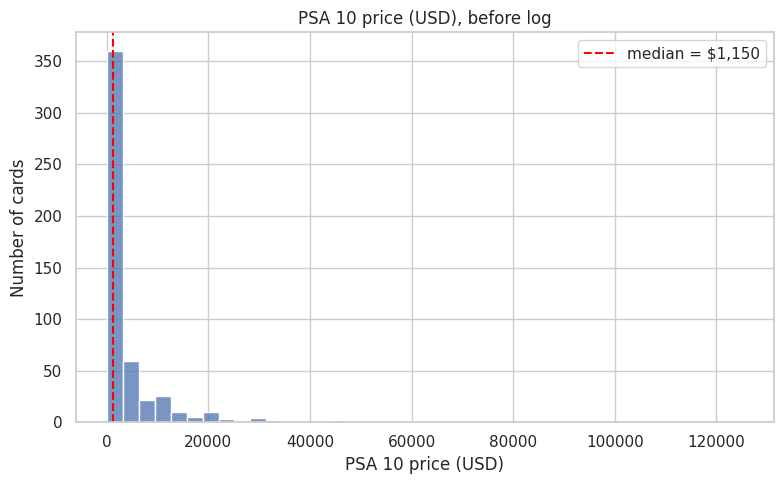

**Figure 1.** The median PSA 10 price is $1,150, but the mean is $4,493 (skew 6.41). 60 cards sell above $10,000, and the 10 most expensive cards make up 25% of all PSA 10 value, so a few cards dominate the market.

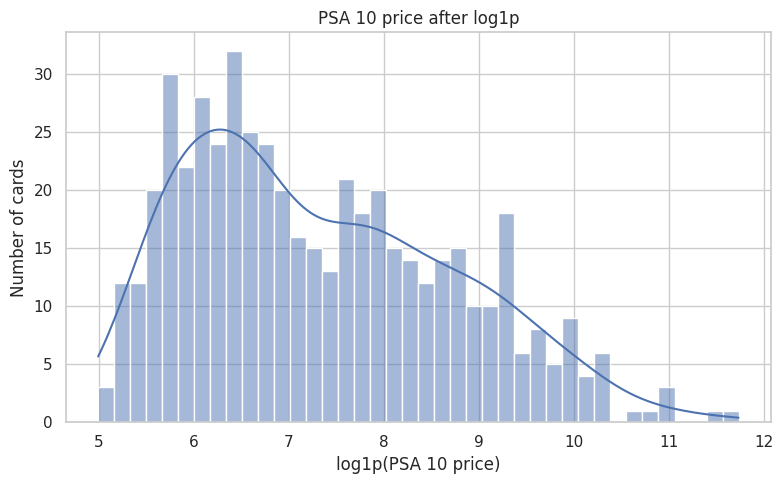

**Figure 2.** After the log1p transform the skew falls from 6.41 to 0.55. The distribution is now close to symmetric, which is why the log columns are used for scaling and modelling.

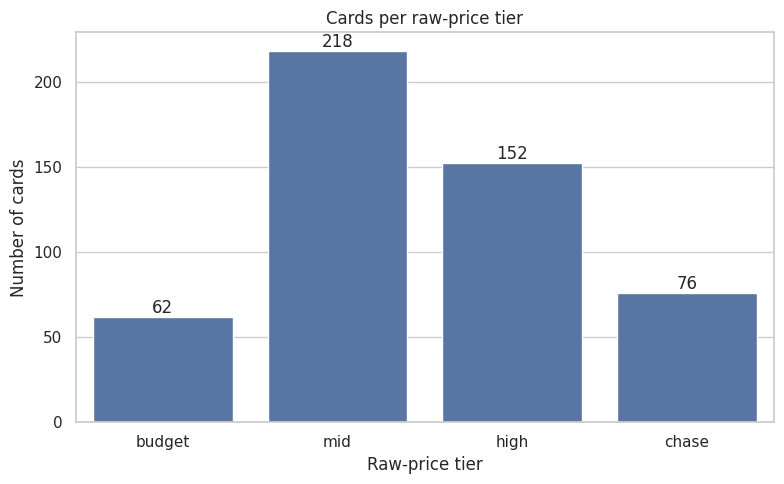

**Figure 3.** Most cards sit in the middle of the market: budget (up to $50 raw) 62, mid ($50 to $150) 218, high ($150 to $500) 152, chase (above $500) 76.

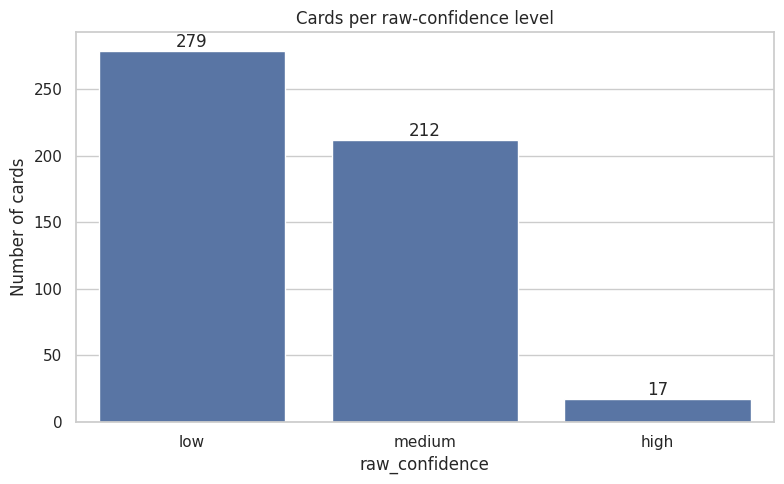

**Figure 4.** 279 of 508 cards (55%) have low raw confidence and only 17 have high confidence, so many raw prices rest on few sales and should be read with caution.

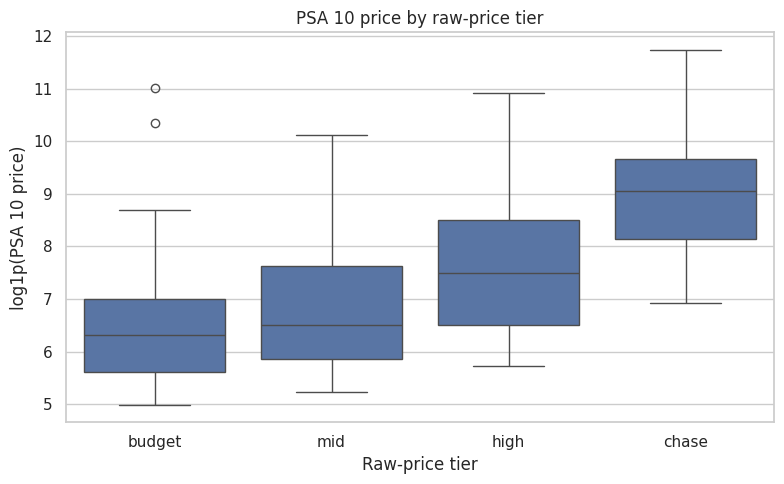

**Figure 5.** The median PSA 10 price rises with the raw tier: $555 (budget), $663 (mid), $1,812 (high), $8,602 (chase). Budget and mid overlap heavily, so raw price separates the upper tiers better than the lower ones.

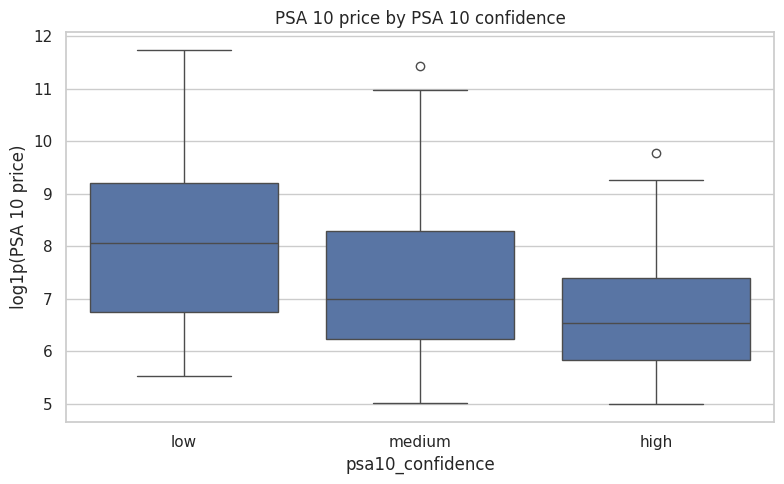

**Figure 6.** Cards with low PSA 10 confidence have the highest median price ($3,167) but the fewest sales (median 11), compared with $688 and 271.5 sales for high confidence. Expensive cards trade rarely, so their prices are less certain.

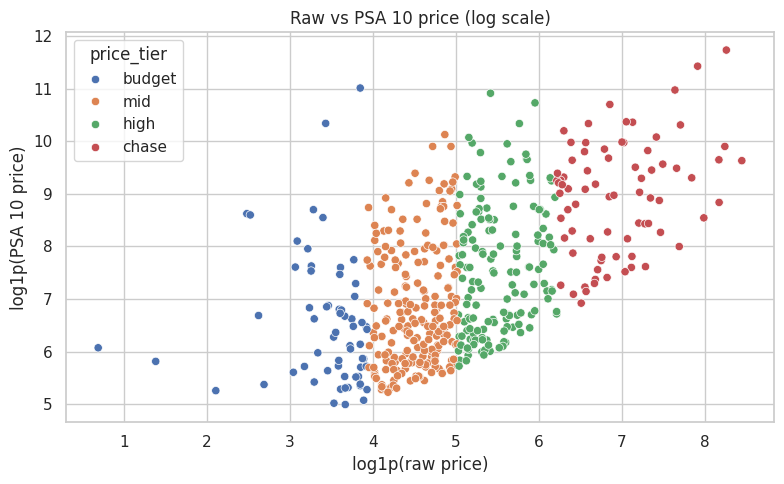

**Figure 7.** Raw and PSA 10 log prices are positively related (r = 0.55) but the scatter is wide, so raw price alone predicts the PSA 10 price only roughly. The median PSA 10 / raw multiple is 15.8x for budget cards versus 7.3x, 6.5x and 7.9x for mid, high and chase.

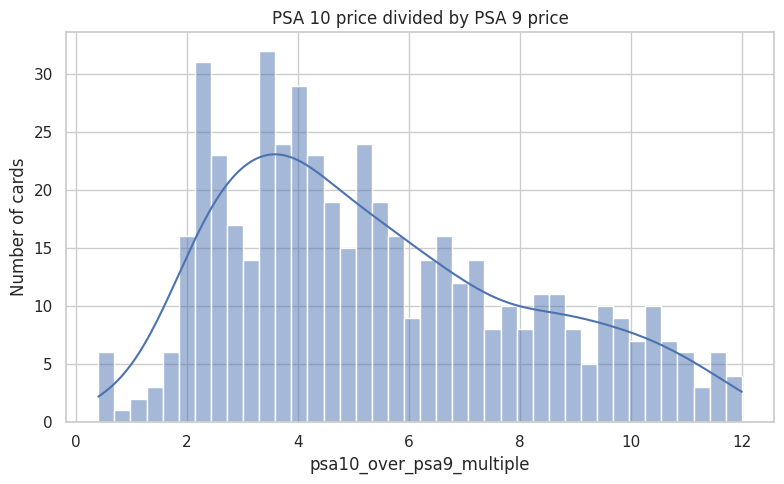

**Figure 8.** A PSA 10 sells for a median of 4.9x the PSA 9 price (middle half: 3.3x to 7.3x). 7 cards fall below 1x, meaning a PSA 10 priced under a PSA 9, which is a data-quality warning.

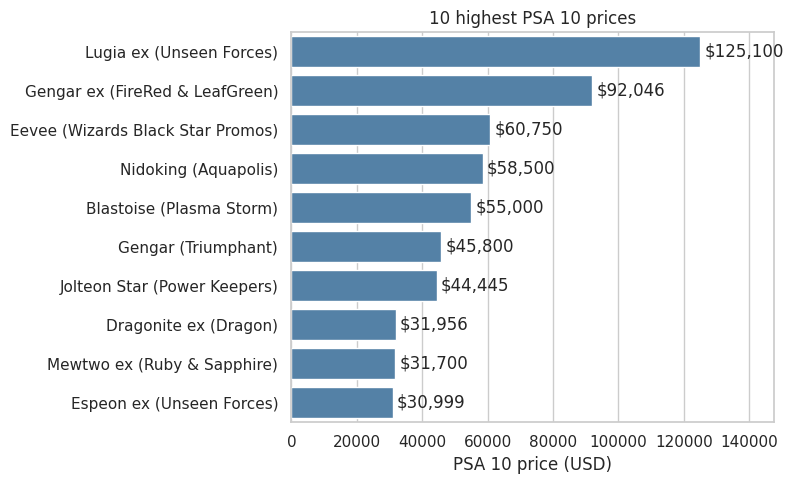

**Figure 9.** The priciest PSA 10 is Lugia ex at $125,100, based on only 5 sales. 6 of these 10 cards have fewer than 10 PSA 10 sales, and 5 are 'ex' cards.

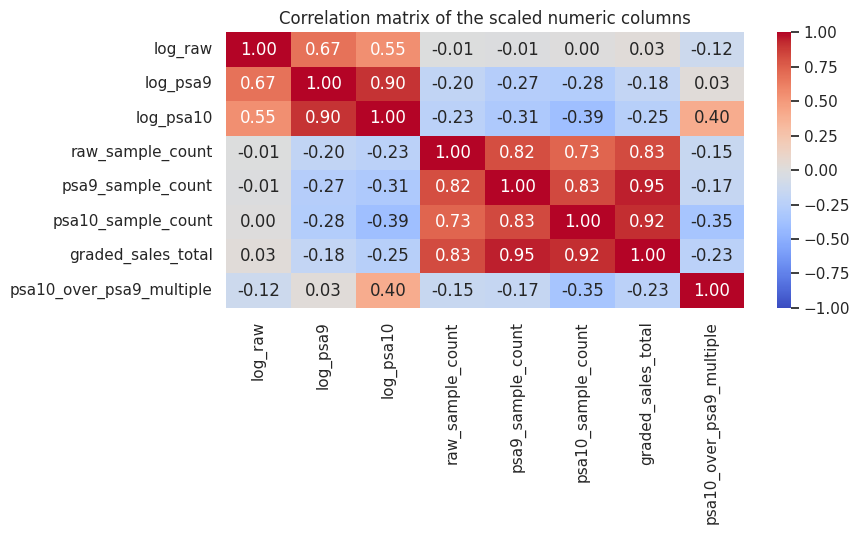

**Figure 10.** The price columns move together (log_psa9 vs log_psa10, r = 0.90). PSA 10 sample count is negatively related to PSA 10 price (r = -0.39), and psa9_sample_count and graded_sales_total carry almost the same signal (r = 0.95), so one of them is redundant for modelling.

Saved: ['plot_1.png', 'plot_10.png', 'plot_2.png', 'plot_3.png', 'plot_4.png', 'plot_5.png', 'plot_6.png', 'plot_7.png', 'plot_8.png', 'plot_9.png']


In [ ]:
i = 0
while i < 10:                                   # decision: More plots? (i < 10)
    spec = plot_list[i]                         # Read plot_list[i]: plot type + column names
    kind = spec['kind']

    # ---- Draw the plot (matplotlib / seaborn), add title and axis labels ----
    fig, ax = plt.subplots(figsize=(9, 5.5) if kind == 'heatmap' else (8, 5))
    if kind == 'hist':
        sns.histplot(data=df_viz, x=spec['x'], bins=40, kde=spec.get('kde', False), ax=ax)
        if spec.get('vline') == 'median':
            med = df_viz[spec['x']].median()
            ax.axvline(med, color='red', linestyle='--', label=f"median = ${med:,.0f}")
            ax.legend()
    elif kind == 'count':
        sns.countplot(data=df_viz, x=spec['x'], order=spec['order'], ax=ax)
        ax.bar_label(ax.containers[0])
    elif kind == 'box':
        sns.boxplot(data=df_viz, x=spec['x'], y=spec['y'], order=spec['order'], ax=ax)
    elif kind == 'scatter':
        sns.scatterplot(data=df_viz, x=spec['x'], y=spec['y'], hue=spec['hue'], hue_order=tier_order, ax=ax)
    elif kind == 'bar':
        top10 = df_viz.nlargest(10, 'psa10_price_usd').copy()
        top10['label'] = top10['name'] + ' (' + top10['set_name'] + ')'
        sns.barplot(data=top10, x='psa10_price_usd', y='label', color='steelblue', ax=ax)
        ax.bar_label(ax.containers[0], fmt='${:,.0f}', padding=3)
        ax.set_xlim(0, top10['psa10_price_usd'].max() * 1.18)
    elif kind == 'heatmap':
        corr = df_viz[scaled_cols].corr()
        corr.index = [c.replace('_scaled', '') for c in corr.index]
        corr.columns = corr.index
        sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(spec['title'])
    ax.set_xlabel(spec['xlabel'])
    ax.set_ylabel(spec['ylabel'])
    plt.tight_layout()

    # ---- OUTPUT: visualizations/plot_{i+1}.png ----
    fig.savefig(f"visualizations/plot_{i+1}.png", dpi=150, bbox_inches='tight')
    plt.show()
    display(Markdown(f"**Figure {i+1}.** {spec['caption']}"))

    i = i + 1                                   # i = i + 1, then back to the decision

print("Saved:", sorted(os.listdir('visualizations')))

In [ ]:
print("Preprocessing finished.")
print("Cleaned dataset:", df_clean.shape, "-> pokemon_cards_clean.csv")

Preprocessing finished.
Cleaned dataset: (508, 38) -> pokemon_cards_clean.csv
